# Lab 02 / Supervised learning and the workflow

**Goal:** fit regression and classification pipelines, validate time series
chronologically, compare decision thresholds, tune using cross-validation,
and save reusable models. Based on `Lab-Activity-Lab02.pdf`.

Run in order using **Python (ml-lab)**. This notebook completes Parts A-E,
the heart-disease extension, the decision memo, and the understanding questions.

**Evaluation correction:** the handout's Part C and Part D use the same
Titanic split, so its nominal final test rows have already been evaluated in
Part C. Here we reserve 25% first, run Part C within the remaining development
rows, tune on development rows only, and evaluate the reserved test once.

In [1]:
LAB = "lab02"

import json
import sys
from pathlib import Path
import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

%matplotlib inline

# Works from the repository root or from all_experiments/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "all_datasets").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA = PROJECT_ROOT / "all_datasets"
OUT = PROJECT_ROOT / "results" / LAB
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
summary = {}

plt.rcParams.update({
    "figure.facecolor": "#0d1117", "axes.facecolor": "#161b22",
    "savefig.facecolor": "#0d1117", "text.color": "#e6edf3",
    "axes.labelcolor": "#c9d1d9", "xtick.color": "#8b949e",
    "ytick.color": "#8b949e", "axes.edgecolor": "#30363d",
    "axes.prop_cycle": matplotlib.cycler(color=["#80e0ff", "#f5b971", "#79d6a4", "#d2a8ff"]),
    "font.size": 10, "axes.titlesize": 12, "figure.dpi": 110,
})

def save_plot(filename):
    plt.gcf().savefig(OUT / filename, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close()

def make_preprocess(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),
    ])

versions = {"python": sys.version.split()[0], "numpy": np.__version__,
            "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
            "scikit_learn": sklearn.__version__, "joblib": joblib.__version__}
summary["versions"] = versions
print("Environment:", versions)
print("Project:", PROJECT_ROOT.name)
print("Interpreter is in an isolated environment:", sys.prefix != sys.base_prefix)
assert sys.prefix != sys.base_prefix, "Select the Python (ml-lab) kernel."

Environment: {'python': '3.12.10', 'numpy': '2.5.1', 'pandas': '3.0.3', 'matplotlib': '3.9.0', 'scikit_learn': '1.9.0', 'joblib': '1.5.3'}
Project: Lab
Interpreter is in an isolated environment: True


In [2]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay,
    RocCurveDisplay, accuracy_score, average_precision_score, classification_report,
    confusion_matrix, mean_absolute_error, mean_squared_error, precision_score,
    r2_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

def regression_metrics(y_true, predictions):
    return {"mae": float(mean_absolute_error(y_true, predictions)),
            "rmse": float(np.sqrt(mean_squared_error(y_true, predictions))),
            "r2": float(r2_score(y_true, predictions))}

## Part A / Insurance charges: ordinary least squares and ridge

The label is `charges`; the remaining six fields are inputs. Both estimators
use the same split and preprocessing. MAE measures average absolute dollar
error, RMSE gives large errors greater influence, and R-squared compares
against predicting the validation-label mean. Ridge shrinks coefficients;
it cannot introduce interactions missing from the feature set.

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


,mae,rmse,r2
linear regression,4181.194,5796.285,0.784
ridge,4238.824,5821.592,0.782


,coefficient
cat__smoker_no,-11825.56
cat__region_southwest,-350.21
cat__region_southeast,-198.28
cat__sex_male,-9.30
cat__sex_female,9.30
cat__region_northwest,88.91
cat__region_northeast,459.59
num__children,516.89
num__bmi,2036.23
num__age,3614.98


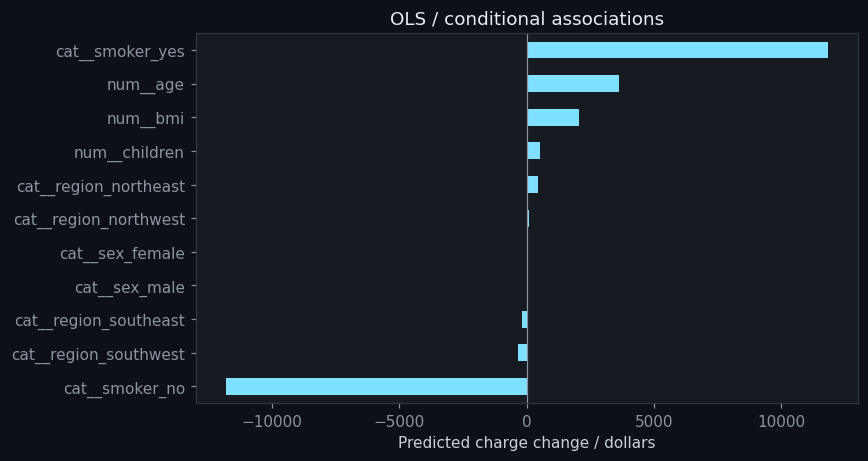

In [3]:
insurance = pd.read_csv(DATA / "medical_cost_personal_dataset.csv")
display(insurance.head())
X = insurance.drop(columns="charges")
y = insurance["charges"]
num_cols = ["age", "bmi", "children"]
cat_cols = ["sex", "smoker", "region"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.20, random_state=SEED)
fitted, predictions, insurance_scores = {}, {}, {}
for name, estimator in {"linear regression": LinearRegression(), "ridge": Ridge(alpha=10.0)}.items():
    pipe = Pipeline([("preprocess", make_preprocess(num_cols, cat_cols)), ("model", estimator)])
    fitted[name] = pipe.fit(X_train, y_train)
    predictions[name] = pipe.predict(X_valid)
    insurance_scores[name] = regression_metrics(y_valid, predictions[name])
display(pd.DataFrame(insurance_scores).T.round(3))
pd.DataFrame(insurance_scores).T.to_csv(OUT / "insurance_metrics.csv", index_label="model")
summary["insurance"] = insurance_scores
linear = fitted["linear regression"]
coefs = pd.Series(linear.named_steps["model"].coef_,
                  index=linear.named_steps["preprocess"].get_feature_names_out()).sort_values()
display(coefs.rename("coefficient").to_frame().round(2))
plt.figure(figsize=(8, 4.3))
coefs.plot.barh()
plt.axvline(0, color="#8b949e", linewidth=0.8)
plt.xlabel("Predicted charge change / dollars")
plt.title("OLS / conditional associations")
plt.tight_layout()
save_plot("insurance_coefficients.png")

Numerical coefficients describe a one-standard-deviation increase because
their inputs were standardized. All levels of each categorical variable
are one-hot encoded, so interpret differences between category coefficients,
not a single coefficient as a unique baseline effect. In particular,
`smoker_yes - smoker_no` is the fitted smoker/non-smoker contrast.
These are predictive associations, not causal estimates.

OLS smoker yes-minus-no contrast: $23,651.13


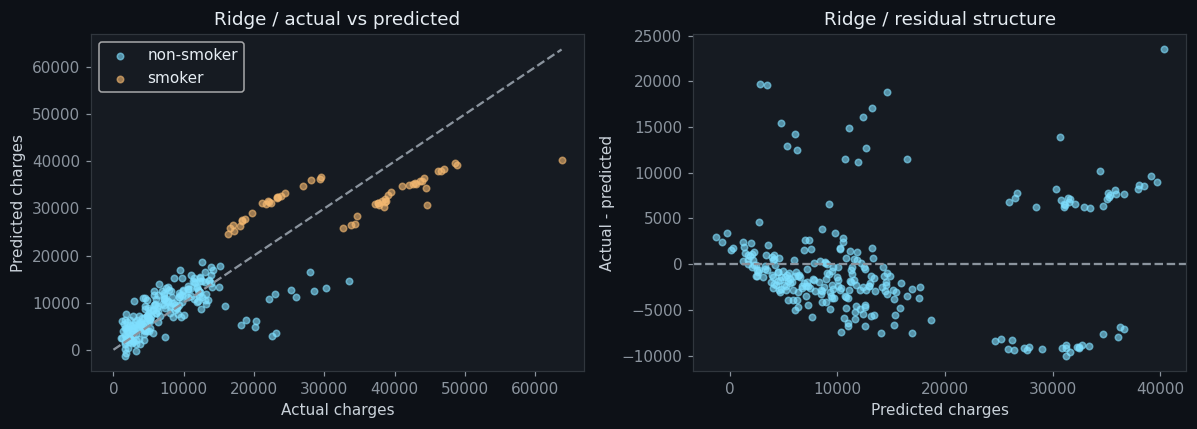

In [4]:
smoker_contrast = float(coefs["cat__smoker_yes"] - coefs["cat__smoker_no"])
print(f"OLS smoker yes-minus-no contrast: ${smoker_contrast:,.2f}")
summary["smoker_contrast_dollars"] = smoker_contrast
ridge_pred = predictions["ridge"]
residual = y_valid.to_numpy() - ridge_pred
is_smoker = (X_valid["smoker"] == "yes").to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for flag, label in [(False, "non-smoker"), (True, "smoker")]:
    mask = is_smoker == flag
    axes[0].scatter(y_valid[mask], ridge_pred[mask], alpha=0.6, s=18, label=label)
axes[0].plot([0, y_valid.max()], [0, y_valid.max()], "--", color="#8b949e")
axes[0].set(xlabel="Actual charges", ylabel="Predicted charges", title="Ridge / actual vs predicted")
axes[0].legend()
axes[1].scatter(ridge_pred, residual, alpha=0.6, s=18)
axes[1].axhline(0, linestyle="--", color="#8b949e")
axes[1].set(xlabel="Predicted charges", ylabel="Actual - predicted", title="Ridge / residual structure")
plt.tight_layout()
save_plot("insurance_residuals.png")

## Part B / Bike rentals: preserve date order

`cnt = casual + registered`, so exclude both component counts and the row ID.
Train on the first 80% and validate on the last 20%. Calendar fields are
categories; weather measurements pass directly to a random forest, whose
splits do not need standardization. Same-day weather inputs describe demand
conditional on weather; a forecast made before the day would need weather
forecasts or lagged weather instead of observed full-day measurements.

Train: 2011-01-01 to 2012-08-06
Valid: 2012-08-07 to 2012-12-31


Daily metrics: {'mae': 1040.4150949117022, 'rmse': 1245.0236575001534, 'r2': 0.5589085465165378, 'validation_mean_demand': 5897.802721088436, 'training_rows': 584, 'validation_rows': 147}


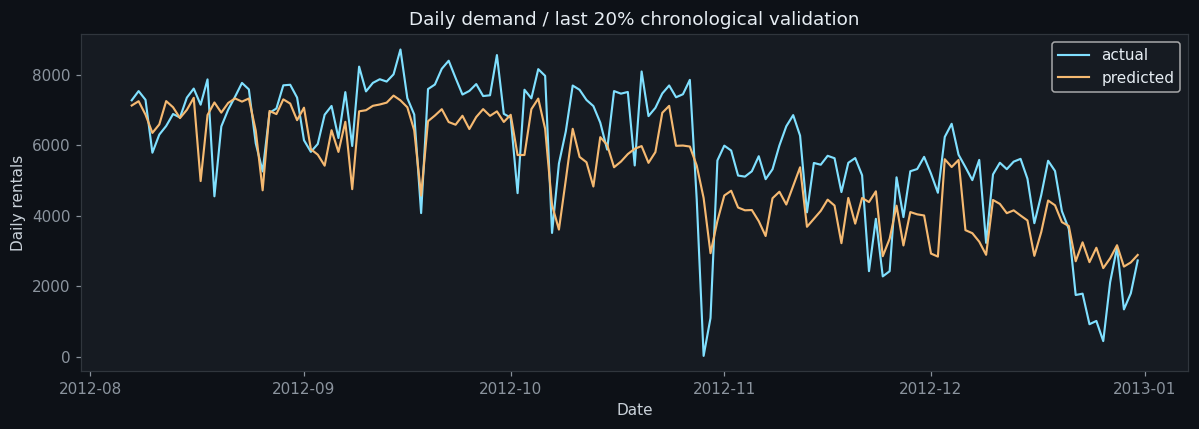

In [5]:
bikes = pd.read_csv(DATA / "bike_sharing_dataset_day.csv")
bikes["dteday"] = pd.to_datetime(bikes["dteday"])
bikes = bikes.sort_values("dteday").reset_index(drop=True)
bike_cat = ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]
bike_num = ["temp", "atemp", "hum", "windspeed"]
X_b, y_b = bikes[bike_cat + bike_num], bikes["cnt"]
cut = int(len(bikes) * 0.80)
assert bikes["dteday"].iloc[cut - 1] < bikes["dteday"].iloc[cut]
assert not {"casual", "registered", "cnt", "instant"}.intersection(X_b.columns)
print("Train:", bikes["dteday"].iloc[0].date(), "to", bikes["dteday"].iloc[cut - 1].date())
print("Valid:", bikes["dteday"].iloc[cut].date(), "to", bikes["dteday"].iloc[-1].date())

def make_bike_model(categories, trees):
    return Pipeline([
        ("preprocess", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), categories),
            ("num", "passthrough", bike_num),
        ])),
        ("model", RandomForestRegressor(n_estimators=trees, min_samples_leaf=2,
                                       random_state=SEED, n_jobs=2)),
    ])

bike_model = make_bike_model(bike_cat, 400).fit(X_b.iloc[:cut], y_b.iloc[:cut])
bike_pred = bike_model.predict(X_b.iloc[cut:])
daily_scores = regression_metrics(y_b.iloc[cut:], bike_pred)
daily_scores["validation_mean_demand"] = float(y_b.iloc[cut:].mean())
daily_scores["training_rows"] = cut
daily_scores["validation_rows"] = len(bikes) - cut
summary["bike_daily"] = daily_scores
print("Daily metrics:", daily_scores)
plt.figure(figsize=(11, 4))
plt.plot(bikes["dteday"].iloc[cut:], y_b.iloc[cut:].to_numpy(), label="actual", linewidth=1.4)
plt.plot(bikes["dteday"].iloc[cut:], bike_pred, label="predicted", linewidth=1.4)
plt.xlabel("Date")
plt.ylabel("Daily rentals")
plt.title("Daily demand / last 20% chronological validation")
plt.legend()
plt.tight_layout()
save_plot("bike_daily_validation.png")

Hourly train: 2011-01-01 00:00:00 to 2012-08-07 11:00:00
Hourly valid: 2012-08-07 12:00:00 to 2012-12-31 23:00:00


Hourly metrics: {'mae': 56.50896598957079, 'rmse': 84.5075294517465, 'r2': 0.8530960634830038, 'validation_mean_demand': 248.75460299194475, 'training_rows': 13903, 'validation_rows': 3476}


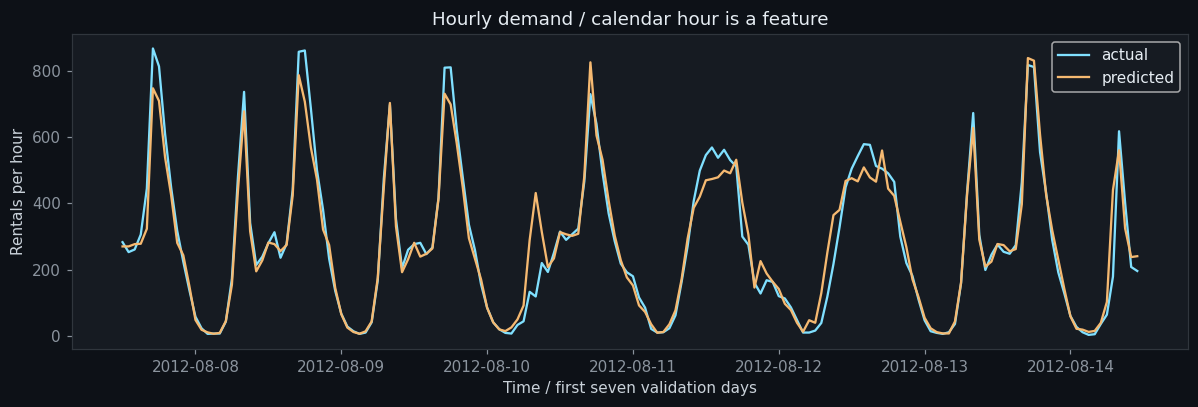

In [6]:
hourly = pd.read_csv(DATA / "bike_sharing_dataset_hour.csv")
hourly["timestamp"] = pd.to_datetime(hourly["dteday"]) + pd.to_timedelta(hourly["hr"], unit="h")
hourly = hourly.sort_values("timestamp").reset_index(drop=True)
hour_cat = bike_cat + ["hr"]
X_h, y_h = hourly[hour_cat + bike_num], hourly["cnt"]
cut_h = int(len(hourly) * 0.80)
assert hourly["timestamp"].iloc[cut_h - 1] < hourly["timestamp"].iloc[cut_h]
assert not {"casual", "registered", "cnt", "instant"}.intersection(X_h.columns)
print("Hourly train:", hourly["timestamp"].iloc[0], "to", hourly["timestamp"].iloc[cut_h - 1])
print("Hourly valid:", hourly["timestamp"].iloc[cut_h], "to", hourly["timestamp"].iloc[-1])
hour_model = make_bike_model(hour_cat, 200).fit(X_h.iloc[:cut_h], y_h.iloc[:cut_h])
hour_pred = hour_model.predict(X_h.iloc[cut_h:])
hour_scores = regression_metrics(y_h.iloc[cut_h:], hour_pred)
hour_scores["validation_mean_demand"] = float(y_h.iloc[cut_h:].mean())
hour_scores["training_rows"] = cut_h
hour_scores["validation_rows"] = len(hourly) - cut_h
summary["bike_hourly"] = hour_scores
print("Hourly metrics:", hour_scores)
week_start = hourly["timestamp"].iloc[cut_h]
week_mask = (hourly["timestamp"].iloc[cut_h:] < week_start + pd.Timedelta(days=7)).to_numpy()
plt.figure(figsize=(11, 3.8))
plt.plot(hourly["timestamp"].iloc[cut_h:][week_mask], y_h.iloc[cut_h:].to_numpy()[week_mask], label="actual")
plt.plot(hourly["timestamp"].iloc[cut_h:][week_mask], hour_pred[week_mask], label="predicted")
plt.xlabel("Time / first seven validation days")
plt.ylabel("Rentals per hour")
plt.title("Hourly demand / calendar hour is a feature")
plt.legend()
plt.tight_layout()
save_plot("bike_hourly_validation.png")

Tree predictions average labels in leaves and cannot extrapolate beyond the
training-label range. Check missed peaks in the daily plot. The hourly plot
uses actual timestamps for seven days, because some hours may be absent;
168 consecutive rows need not equal exactly one week.

## Part C / Titanic baselines and decision rules

Reserve the final test now. Use a separate validation split *within* the
development partition for model comparison. The majority baseline always
predicts the common training class. Accuracy uses a classification decision;
ROC AUC uses probability ranking. Only development labels guide model choices.

Rows: development 668 / final test 223
Part C: training 501 / validation 167
Majority-class validation accuracy: 0.617


,accuracy,roc_auc
logistic,0.8204,0.8730
random_forest,0.8323,0.9093


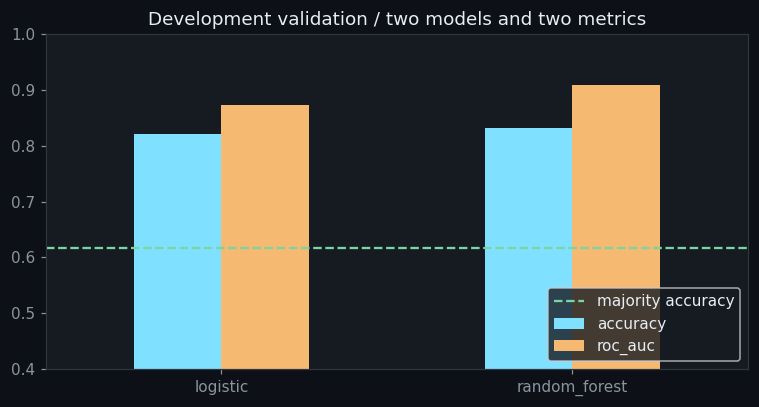

In [7]:
titanic = pd.read_csv(DATA / "titanic_dataset.csv")
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
t_num = ["Age", "SibSp", "Parch", "Fare"]
t_cat = ["Pclass", "Sex", "Embarked"]
X_t, y_t = titanic[features], titanic["Survived"]
X_dev, X_test, y_dev, y_test = train_test_split(X_t, y_t, test_size=0.25,
                                              random_state=SEED, stratify=y_t)
Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(X_dev, y_dev, test_size=0.25,
                                                       random_state=SEED, stratify=y_dev)
assert set(X_dev.index).isdisjoint(X_test.index)
assert set(Xt_train.index).isdisjoint(Xt_valid.index)
assert set(Xt_valid.index).isdisjoint(X_test.index)
print("Rows: development", len(X_dev), "/ final test", len(X_test))
print("Part C: training", len(Xt_train), "/ validation", len(Xt_valid))
majority_class = int(yt_train.mode().iloc[0])
baseline_accuracy = float(accuracy_score(yt_valid, np.full(len(yt_valid), majority_class)))
print("Majority-class validation accuracy:", round(baseline_accuracy, 3))
scores, fitted_t = {}, {}
for name, estimator in {
    "logistic": LogisticRegression(max_iter=2000),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                            random_state=SEED, n_jobs=2),
}.items():
    pipe = Pipeline([("preprocess", make_preprocess(t_num, t_cat)), ("model", estimator)])
    fitted_t[name] = pipe.fit(Xt_train, yt_train)
    probability = pipe.predict_proba(Xt_valid)[:, 1]
    scores[name] = {"accuracy": float(accuracy_score(yt_valid, pipe.predict(Xt_valid))),
                   "roc_auc": float(roc_auc_score(yt_valid, probability))}
display(pd.DataFrame(scores).T.round(4))
summary["titanic_validation"] = scores
summary["titanic_majority_baseline"] = baseline_accuracy
pd.DataFrame(scores).T.plot.bar(figsize=(7, 3.8), ylim=(0.4, 1.0), rot=0)
plt.axhline(baseline_accuracy, linestyle="--", color="#79d6a4", label="majority accuracy")
plt.title("Development validation / two models and two metrics")
plt.legend(loc="lower right")
plt.tight_layout()
save_plot("titanic_baselines.png")

In [8]:
prob_t = fitted_t["logistic"].predict_proba(Xt_valid)[:, 1]
titanic_thresholds = []
for threshold in [0.30, 0.50, 0.70]:
    pred = (prob_t >= threshold).astype(int)
    titanic_thresholds.append({"threshold": threshold,
        "precision": float(precision_score(yt_valid, pred, zero_division=0)),
        "recall": float(recall_score(yt_valid, pred))})
display(pd.DataFrame(titanic_thresholds).round(4))
summary["titanic_thresholds"] = titanic_thresholds

,threshold,precision,recall
0,0.3,0.6709,0.8281
1,0.5,0.7931,0.7188
2,0.7,0.8947,0.5312


### Breast cancer / probabilities, confusion matrices, ROC and PR

`M` (malignant) is the positive class. Remove the ID and empty trailing
column. Standardization is learned inside the training pipeline.
For a confusion matrix, rows are true classes and columns are predicted
classes: `[[TN, FP], [FN, TP]]`. A lower threshold can increase alerts and
cannot reduce recall on fixed probabilities.

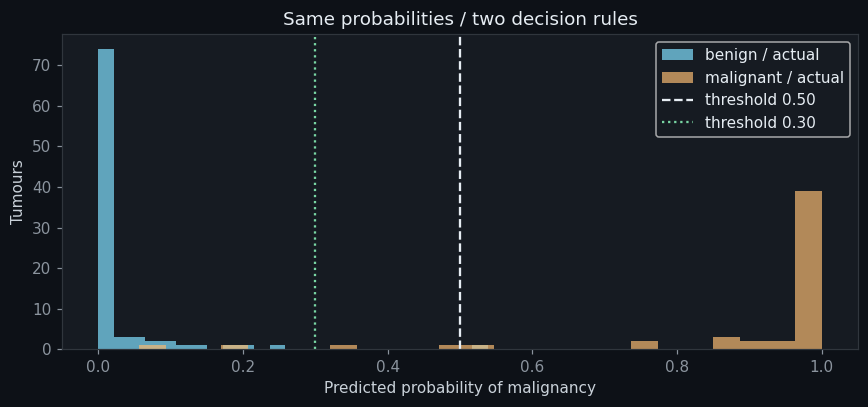

In [9]:
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")
X_c = cancer.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore")
y_c = (cancer["diagnosis"] == "M").astype(int)
Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(X_c, y_c, test_size=0.25,
                                                       random_state=SEED, stratify=y_c)
cancer_model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
]).fit(Xc_train, yc_train)
prob = cancer_model.predict_proba(Xc_valid)[:, 1]
plt.figure(figsize=(8, 3.8))
plt.hist(prob[yc_valid == 0], bins=25, alpha=0.7, label="benign / actual")
plt.hist(prob[yc_valid == 1], bins=25, alpha=0.7, label="malignant / actual")
plt.axvline(0.50, color="#e6edf3", linestyle="--", label="threshold 0.50")
plt.axvline(0.30, color="#79d6a4", linestyle=":", label="threshold 0.30")
plt.xlabel("Predicted probability of malignancy")
plt.ylabel("Tumours")
plt.title("Same probabilities / two decision rules")
plt.legend()
plt.tight_layout()
save_plot("cancer_probabilities.png")

Threshold 0.50
              precision    recall  f1-score   support

      benign      0.957     0.989     0.973        90
   malignant      0.980     0.925     0.951        53

    accuracy                          0.965       143
   macro avg      0.968     0.957     0.962       143
weighted avg      0.966     0.965     0.965       143

Threshold 0.30
              precision    recall  f1-score   support

      benign      0.978     0.989     0.983        90
   malignant      0.981     0.962     0.971        53

    accuracy                          0.979       143
   macro avg      0.979     0.976     0.977       143
weighted avg      0.979     0.979     0.979       143



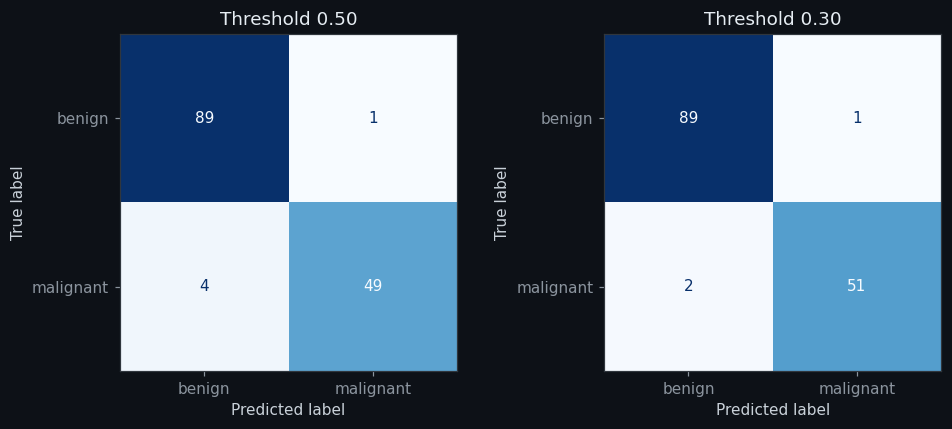

,threshold,tn,fp,fn,tp,precision,recall
0,0.5,89,1,4,49,0.9800,0.9245
1,0.3,89,1,2,51,0.9808,0.9623


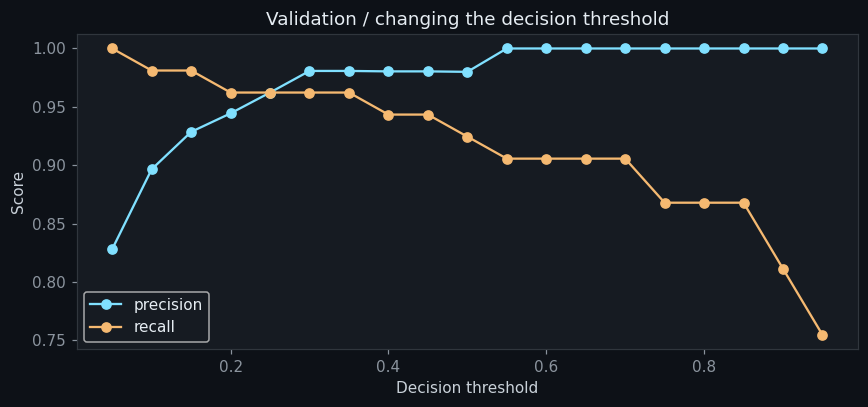

In [10]:
cancer_thresholds = []
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, threshold in zip(axes, [0.50, 0.30]):
    pred = (prob >= threshold).astype(int)
    matrix = confusion_matrix(yc_valid, pred, labels=[0, 1])
    tn, fp, fn, tp = map(int, matrix.ravel())
    cancer_thresholds.append({"threshold": threshold, "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "precision": float(precision_score(yc_valid, pred, zero_division=0)),
        "recall": float(recall_score(yc_valid, pred))})
    print(f"Threshold {threshold:.2f}")
    print(classification_report(yc_valid, pred, target_names=["benign", "malignant"], digits=3))
    ConfusionMatrixDisplay(matrix, display_labels=["benign", "malignant"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Threshold {threshold:.2f}")
plt.tight_layout()
save_plot("cancer_confusion_matrices.png")
display(pd.DataFrame(cancer_thresholds).round(4))
pd.DataFrame(cancer_thresholds).to_csv(OUT / "cancer_thresholds.csv", index=False)
summary["cancer_thresholds"] = cancer_thresholds
assert cancer_thresholds[1]["recall"] >= cancer_thresholds[0]["recall"]
thresholds = np.linspace(0.05, 0.95, 19)
precisions = [precision_score(yc_valid, (prob >= t).astype(int), zero_division=0) for t in thresholds]
recalls = [recall_score(yc_valid, (prob >= t).astype(int)) for t in thresholds]
plt.figure(figsize=(8, 3.8))
plt.plot(thresholds, precisions, marker="o", label="precision")
plt.plot(thresholds, recalls, marker="o", label="recall")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Validation / changing the decision threshold")
plt.legend()
plt.tight_layout()
save_plot("cancer_threshold_tradeoff.png")

Breast-cancer validation metrics: {'roc_auc': 0.9962264150943396, 'average_precision': 0.9942992040793095}


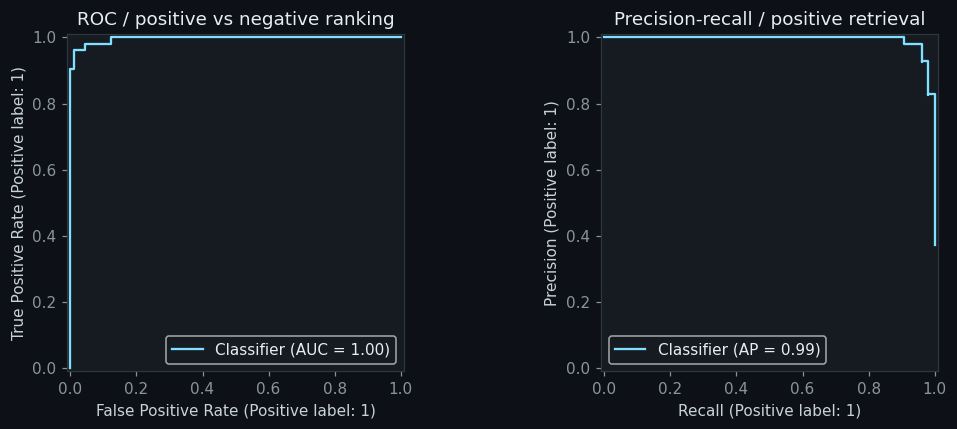

In [11]:
cancer_scores = {"roc_auc": float(roc_auc_score(yc_valid, prob)),
                 "average_precision": float(average_precision_score(yc_valid, prob))}
print("Breast-cancer validation metrics:", cancer_scores)
summary["cancer"] = cancer_scores
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(yc_valid, prob, ax=axes[0])
axes[0].set_title("ROC / positive vs negative ranking")
PrecisionRecallDisplay.from_predictions(yc_valid, prob, ax=axes[1])
axes[1].set_title("Precision-recall / positive retrieval")
plt.tight_layout()
save_plot("cancer_roc_pr.png")

Average precision summarizes precision-recall using recall increments; it
is not exactly the trapezoidal area under a PR curve. Both the score and
the plotted curve use the same validation probabilities.

### Decision memo / Missed positives cost more

Compare 0.50 and 0.30 using the observed validation confusion matrices.
Choose a provisional lower threshold when its additional false alerts are
acceptable for the reduction in missed positives. This is a coursework
decision on one dataset, not a validated clinical operating policy.

In [12]:
high, low = cancer_thresholds
memo = (
    "# Lab 02 / Decision memo\n\n"
    "Positive class: malignant. Among the two specified thresholds, choose **0.30** "
    "provisionally when missed positives cost more than false alarms.\n\n"
    f"At 0.50: TN={high['tn']}, FP={high['fp']}, FN={high['fn']}, TP={high['tp']}; "
    f"precision={high['precision']:.3f}, recall={high['recall']:.3f}.\n\n"
    f"At 0.30: TN={low['tn']}, FP={low['fp']}, FN={low['fn']}, TP={low['tp']}; "
    f"precision={low['precision']:.3f}, recall={low['recall']:.3f}.\n\n"
    f"Lowering the threshold avoids {high['fn'] - low['fn']} missed positives "
    f"and adds {low['fp'] - high['fp']} false alerts in this validation sample. "
    "The probability model is unchanged; only its decision rule changes. "
    "An exact optimum requires specified error costs, calibration, and separate "
    "evaluation of the chosen threshold. These 143 validation rows support a "
    "provisional coursework choice, not deployment.\n"
)
(OUT / "decision_memo.md").write_text(memo, encoding="utf-8")
print(memo)

# Lab 02 / Decision memo

Positive class: malignant. Among the two specified thresholds, choose **0.30** provisionally when missed positives cost more than false alarms.

At 0.50: TN=89, FP=1, FN=4, TP=49; precision=0.980, recall=0.925.

At 0.30: TN=89, FP=1, FN=2, TP=51; precision=0.981, recall=0.962.

Lowering the threshold avoids 2 missed positives and adds 0 false alerts in this validation sample. The probability model is unchanged; only its decision rule changes. An exact optimum requires specified error costs, calibration, and separate evaluation of the chosen threshold. These 143 validation rows support a provisional coursework choice, not deployment.



## Part D / Tune on development rows, then test once

Tune `C` and `class_weight` with five stratified folds. Preprocessing is
refitted inside every fold. Higher `C` means weaker regularization.
The grid chooses by mean ROC AUC, so the threshold remains the predeclared
0.50; we do not tune it on the final test. Fold standard deviations describe
variation between folds, not confidence intervals.

Best parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Mean cross-validated ROC AUC: 0.85


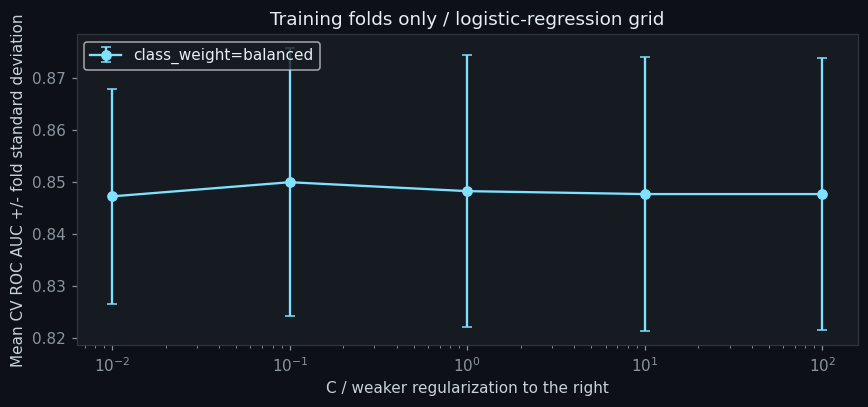

In [13]:
search = GridSearchCV(
    Pipeline([("preprocess", make_preprocess(t_num, t_cat)),
              ("model", LogisticRegression(max_iter=2000))]),
    param_grid={"model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
                "model__class_weight": [None, "balanced"]},
    scoring="roc_auc", cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    n_jobs=2,
)
with joblib.parallel_backend("threading"):
    search.fit(X_dev, y_dev)
cv_table = pd.DataFrame(search.cv_results_)
cv_table[["param_model__C", "param_model__class_weight", "mean_test_score", "std_test_score",
          "rank_test_score"]].to_csv(OUT / "titanic_cv_results.csv", index=False)
print("Best parameters:", search.best_params_)
print("Mean cross-validated ROC AUC:", round(search.best_score_, 4))
plt.figure(figsize=(8, 3.8))
for weight, group in cv_table.groupby(cv_table["param_model__class_weight"].astype(str)):
    plt.errorbar(group["param_model__C"].astype(float), group["mean_test_score"],
                 yerr=group["std_test_score"], marker="o", capsize=3, label=f"class_weight={weight}")
plt.xscale("log")
plt.xlabel("C / weaker regularization to the right")
plt.ylabel("Mean CV ROC AUC +/- fold standard deviation")
plt.title("Training folds only / logistic-regression grid")
plt.legend()
plt.tight_layout()
save_plot("titanic_cross_validation.png")

In [14]:
# First and only final-test evaluation in this workflow.
test_prob = search.predict_proba(X_test)[:, 1]
test_auc = float(roc_auc_score(y_test, test_prob))
test_accuracy = float(accuracy_score(y_test, test_prob >= 0.5))
print(f"Final test: ROC AUC={test_auc:.4f}, accuracy={test_accuracy:.4f}")
summary["titanic_final"] = {"best_parameters": search.best_params_,
    "cv_roc_auc": float(search.best_score_), "test_roc_auc": test_auc,
    "test_accuracy": test_accuracy, "development_rows": len(X_dev), "test_rows": len(X_test),
    "decision_threshold": 0.5}
# Row indices make the partitions auditable, without exporting test labels.
pd.Series(X_dev.index, name="row_index").to_csv(OUT / "titanic_development_rows.csv", index=False)
pd.Series(X_test.index, name="row_index").to_csv(OUT / "titanic_test_rows.csv", index=False)

Final test: ROC AUC=0.8374, accuracy=0.7578


## Part E / Save, reload, and predict new rows

Save the whole preprocessing-and-model pipeline, not only its classifier.
The model card records features, versions, evaluation, and the threshold.
Only load joblib files you trust: deserialization can execute code.
The examples below are new input rows and use no training step.

In [15]:
final_model = search.best_estimator_
model_path = MODELS / "titanic_survival.joblib"
joblib.dump(final_model, model_path)
card = {
    "task": "predict Titanic survival (1 = survived)", "features": features,
    "model": "logistic regression pipeline", "best_parameters": search.best_params_,
    "training_rows": len(X_dev), "test_rows": len(X_test),
    "cross_validated_roc_auc": round(float(search.best_score_), 4),
    "final_test_roc_auc": round(test_auc, 4), "final_test_accuracy": round(test_accuracy, 4),
    "decision_threshold": 0.5, "scikit_learn_version": sklearn.__version__,
    "versions": versions, "random_state": SEED,
    "evaluation": "25% held out before Part C; five-fold tuning on development rows; test evaluated once",
}
(MODELS / "titanic_survival_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")
loaded = joblib.load(model_path)
new_passengers = pd.DataFrame([
    {"Pclass": 1, "Sex": "female", "Age": 29, "SibSp": 0, "Parch": 0, "Fare": 80.0, "Embarked": "C"},
    {"Pclass": 3, "Sex": "male", "Age": 40, "SibSp": 0, "Parch": 0, "Fare": 7.9, "Embarked": "S"},
])[features]
before = final_model.predict_proba(new_passengers)[:, 1]
after = loaded.predict_proba(new_passengers)[:, 1]
np.testing.assert_allclose(before, after)
new_passengers["survival_probability"] = after.round(4)
display(new_passengers)
print(f"Saved {model_path.name}: {model_path.stat().st_size / 1024:.1f} KB; reload predictions match")
joblib.dump(fitted["linear regression"], MODELS / "insurance_charges.joblib")
pricing = joblib.load(MODELS / "insurance_charges.joblib")
new_customer = pd.DataFrame([
    {"age": 35, "sex": "female", "bmi": 27.5, "children": 2, "smoker": "no", "region": "southeast"},
    {"age": 35, "sex": "female", "bmi": 27.5, "children": 2, "smoker": "yes", "region": "southeast"},
])
new_customer["predicted_charges"] = pricing.predict(new_customer).round(2)
display(new_customer)
summary["saved_model_reload_matches"] = True
(MODELS / "insurance_charges_card.json").write_text(json.dumps({
    "task": "predict insurance charges", "features": X.columns.tolist(),
    "model": "linear regression pipeline", "training_rows": len(X_train),
    "validation_rows": len(X_valid), "validation_metrics": insurance_scores["linear regression"],
    "versions": versions, "random_state": SEED,
}, indent=2), encoding="utf-8")

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,survival_probability
0,1,female,29,0,0,80.0,C,0.9421
1,3,male,40,0,0,7.9,S,0.1412


Saved titanic_survival.joblib: 4.5 KB; reload predictions match


,age,sex,bmi,children,smoker,region,predicted_charges
0,35,female,27.5,2,no,southeast,6525.67
1,35,female,27.5,2,yes,southeast,30176.80


543

From the project root, use the environment's Python:

```powershell
.\.venv\Scripts\python.exe predict_passenger.py --pclass 2 --sex female --age 30 --fare 20
```

The CLI checks for the saved files and validates nonnegative counts and fares.
It also works when invoked from a different working directory.

## Try it yourself / Heart disease

Predict `HeartDisease` with numeric and text columns discovered from dtypes.
Use the same preprocessing helper and a stratified validation split.
Integer-coded categories stay numeric for this handout exercise; explicit
semantic column typing could be explored separately.

Numeric: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak'] Categorical: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


Heart-disease validation: {'accuracy': 0.8826086956521739, 'roc_auc': 0.9320388349514562, 'confusion_matrix': [[86, 17], [10, 117]]}
              precision    recall  f1-score   support

           0      0.896     0.835     0.864       103
           1      0.873     0.921     0.897       127

    accuracy                          0.883       230
   macro avg      0.884     0.878     0.880       230
weighted avg      0.883     0.883     0.882       230



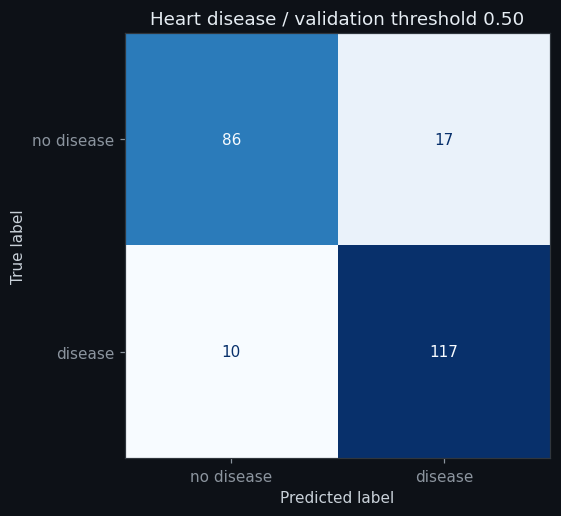

2561

In [16]:
heart = pd.read_csv(DATA / "heart_failure_dataset.csv")
X_heart, y_heart = heart.drop(columns="HeartDisease"), heart["HeartDisease"]
h_num = X_heart.select_dtypes(include="number").columns.tolist()
h_cat = X_heart.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", h_num, "Categorical:", h_cat)
Xh_train, Xh_valid, yh_train, yh_valid = train_test_split(X_heart, y_heart, test_size=0.25,
                                                       random_state=SEED, stratify=y_heart)
heart_model = Pipeline([
    ("preprocess", make_preprocess(h_num, h_cat)),
    ("model", LogisticRegression(max_iter=2000)),
]).fit(Xh_train, yh_train)
heart_prob = heart_model.predict_proba(Xh_valid)[:, 1]
heart_pred = (heart_prob >= 0.5).astype(int)
heart_scores = {"accuracy": float(accuracy_score(yh_valid, heart_pred)),
                "roc_auc": float(roc_auc_score(yh_valid, heart_prob)),
                "confusion_matrix": confusion_matrix(yh_valid, heart_pred, labels=[0, 1]).tolist()}
print("Heart-disease validation:", heart_scores)
print(classification_report(yh_valid, heart_pred, digits=3))
ConfusionMatrixDisplay.from_predictions(yh_valid, heart_pred, display_labels=["no disease", "disease"],
                                        cmap="Blues", colorbar=False)
plt.title("Heart disease / validation threshold 0.50")
plt.tight_layout()
save_plot("heart_confusion_matrix.png")
summary["heart"] = heart_scores
(OUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

## Check your understanding / Worked answers

1. **Why is logistic regression a linear classifier?** It learns a linear
   score, `w^T x + b`, and applies a sigmoid to get a probability. The 0.50
   boundary is where that score equals zero, a hyperplane. Other fixed
   thresholds shift the boundary; the sigmoid does not curve it in the
   transformed feature space.
2. **Why separate probabilities from thresholds?** Probabilities rank and
   quantify model scores; a threshold turns them into actions based on
   error costs and capacity. We can change the operational rule without
   refitting the probability model. Tune that rule on development evidence
   and evaluate the selected rule on separate held-out data.
3. **What changes with multiclass softmax?** There is a linear score per
   class. Softmax normalizes exponentiated scores to probabilities that sum
   to one, and the usual decision chooses the largest probability. Training
   uses multiclass cross-entropy; evaluation needs class-wise or aggregated
   metrics rather than a single positive-class threshold.

## Chapter 4 supplement / Worked answers

1. Supervised learning uses labels; unsupervised learning has no external
   labels; limited-label learning combines a small labelled subset with
   unlabelled examples or selectively requested labels; reinforcement
   learning uses rewards from actions and transitions.
2. All need trustworthy data and monitoring, but the feedback determines
   the fitting objective: prediction loss, structure/reconstruction, or
   expected long-term return.
3. Reducing training loss only shows fit on examples already seen.
   Generalization requires evaluation on unseen examples with a split that
   matches the intended use, such as future dates for demand forecasting.

The saved cards, CV table, split indices, decision memo, and summary JSON are
the evidence for this run. Re-running the notebook recreates them.